# Lab 8: Operating on a Pretrained Network

## ✅ Solution version

All `???` gaps are filled in, and a **Solution and discussion** box follows every set of questions. Your own numbers will differ somewhat from run to run; what matters is whether you can explain the patterns.

**Before you start: Runtime → Change runtime type → GPU.**

## The idea of this lab

This week's lecture showed how CNN architectures are **built**: stacks of convolutions, 1×1
bottlenecks, residual blocks, depthwise-separable factorisations. This lab teaches you how to
customize a network someone else built and trained - this is relevant to your course project if
you want to adapt an existing network to your problem, for instance if you want to input extra
metadata that is not an image (e.g., patient age or gender), or if your images have more than the
default 3 channels (e.g., when working with multi-spectral satellite images).

The key insight is simple, but it changes how you think about your project:

> **A pretrained network is not a black box. It is a collection of tensors (weights) arranged in
> modules, and you can inspect, replace, freeze, extend and merge them.**

Once you see a network this way, many project ideas become a few lines of code: a different
number of input channels, a different output, training only a small part of the network, adding
information (metadata) that isn't an image, and so on.

| Part | You operate on… | You will… |
|---|---|---|
| 0. Look inside | the whole network | count parameters by hand, and find where they are |
| 1. Input surgery | the first layer | adapt a 3-channel network to 1 or more channels, and *prove* it behaves as intended |
| 2. What to train | the training strategy | implement **LoRA** (not covered in the lectures) and compare five ways of adapting a pretrained ResNet |
| 3. Merge and ship | the trained adapter | fold LoRA back into the network, for free |
| 4. Your project | — | turn these operations into ideas for your own project |
| 5. Exam-style questions | — | check your understanding |

Then complete this week's pages in your **iteration log** (`Lab8_IterationLog_Week8.md`).

**Cells marked 🛠️ TASK contain gaps (`???`) that you must fill in.** Most come with a test cell; don't
move on until the tests pass. As in Labs 6–7, write down your ✍️ **Prediction** before running an
experiment, and remember that the goal is to **explain** what you observe, not to get the highest
accuracy.

### ⚠️ The limits of this lab

We use **SVHN** again, with only **2,000 training images** at their native 32×32 resolution, and short
training runs (15 epochs, 2 seeds). ImageNet-pretrained networks expect photos of objects at
224×224, not small crops of digits. That mismatch is deliberate: it makes the differences between the
strategies visible. But conclusions such as "strategy X is best" are conclusions about **this**
setup. Carry the *operations* and the *way of reasoning* into your project, not the numbers.

## Setup

In [4]:
import copy
import math
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print(f'Using device: {device}')


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


N_TRAIN, N_VAL = 2_000, 2_000     # the small-data setting from Lab 7, Part 5 (same images, same validation set)
BATCH_SIZE, NUM_CLASSES, EPOCHS, IMG_SIZE = 64, 10, 15, 32

svhn = torchvision.datasets.SVHN(root='./data', split='train', download=True)
perm = torch.randperm(len(svhn), generator=torch.Generator().manual_seed(0))
train_idx, val_idx = perm[:N_TRAIN], perm[10_000:10_000 + N_VAL]

# A pretrained network expects the preprocessing it was trained with (Lecture 6): ImageNet statistics.
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def load_subset(idx):
    x = torch.from_numpy(svhn.data[idx.numpy()]).float() / 255.0
    y = torch.from_numpy(np.asarray(svhn.labels)[idx.numpy()]).long()
    return ((x - IMAGENET_MEAN) / IMAGENET_STD).to(device), y.to(device)


x_train, y_train = load_subset(train_idx)
x_val, y_val = load_subset(val_idx)
print(f'Train: {tuple(x_train.shape)}, Val: {tuple(x_val.shape)}  (input size {IMG_SIZE}x{IMG_SIZE})')


def prep(xb, model):
    '''Convert to 1 channel if the model expects grayscale input (Part 1); resize if IMG_SIZE differs from 32.'''
    if getattr(model, 'input_mode', 'rgb') == 'gray':
        xb = xb.mean(dim=1, keepdim=True)
    if xb.shape[-1] != IMG_SIZE:
        xb = F.interpolate(xb, size=IMG_SIZE, mode='bilinear', align_corners=False)
    return xb


def batches(x, y, batch_size=BATCH_SIZE, shuffle=True):
    order = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for i in range(0, len(x), batch_size):
        idx = order[i:i + batch_size]
        yield x[idx], y[idx]


ce = nn.CrossEntropyLoss()


@torch.no_grad()
def evaluate(model, x, y, batch_size=256):
    model.eval()
    total_loss, correct = 0.0, 0
    for xb, yb in batches(x, y, batch_size, shuffle=False):
        logits = model(prep(xb, model))
        total_loss += ce(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(x), correct / len(x)


def count_params(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

Using device: cuda
Train: (2000, 3, 32, 32), Val: (2000, 3, 32, 32)  (input size 32x32)


---
## Part 0: Look inside the network

We use **ResNet-18** from this week's lecture, pretrained on ImageNet. Let's look at it as a
collection of tensors.

In [5]:
net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
for name, p in list(net.named_parameters())[:6]:
    print(f'{name:<28} {str(tuple(p.shape)):<20} {p.numel():>9,} parameters')
print('...')
for name, p in list(net.named_parameters())[-2:]:
    print(f'{name:<28} {str(tuple(p.shape)):<20} {p.numel():>9,} parameters')

conv1.weight                 (64, 3, 7, 7)            9,408 parameters
bn1.weight                   (64,)                       64 parameters
bn1.bias                     (64,)                       64 parameters
layer1.0.conv1.weight        (64, 64, 3, 3)          36,864 parameters
layer1.0.bn1.weight          (64,)                       64 parameters
layer1.0.bn1.bias            (64,)                       64 parameters
...
fc.weight                    (1000, 512)            512,000 parameters
fc.bias                      (1000,)                  1,000 parameters


### 🛠️ Task 0 — where are the parameters?

Before running the next cell, use the lecture's formula (parameters of a conv layer =
C_out × C_in × k × k, plus biases) to predict:

1. the number of parameters in `conv1` (64 filters of size 7×7 over 3 input channels, no bias);
2. the number of parameters in **one** 3×3 conv layer inside `layer4` (512 → 512 channels, no bias);
3. which of the four stages (`layer1` … `layer4`) holds the most parameters, and roughly what fraction
   of the total.

Write your predictions here: ✍️

In [6]:
total = count_params(net, trainable_only=False)
print(f'conv1:              {net.conv1.weight.numel():>11,}')
print(f'one layer4 3x3 conv: {net.layer4[1].conv1.weight.numel():>10,}')
for stage in ['conv1', 'bn1', 'layer1', 'layer2', 'layer3', 'layer4', 'fc']:
    n = sum(p.numel() for p in getattr(net, stage).parameters())
    print(f'{stage:<8} {n:>11,} parameters  ({n / total:6.1%})')
print(f'total    {total:>11,}')

conv1:                    9,408
one layer4 3x3 conv:  2,359,296
conv1          9,408 parameters  (  0.1%)
bn1              128 parameters  (  0.0%)
layer1       147,968 parameters  (  1.3%)
layer2       525,568 parameters  (  4.5%)
layer3     2,099,712 parameters  ( 18.0%)
layer4     8,393,728 parameters  ( 71.8%)
fc           513,000 parameters  (  4.4%)
total     11,689,512


**Questions:**

1. The first layer, which sees the raw pixels, holds a tiny fraction of the parameters. The last
   stage holds about three-quarters. Why does the parameter count grow so fast with depth, even though
   the spatial resolution shrinks? (Hint: look at the formula: what grows from stage to stage?)
2. What does this mean for the *cost* of changing the input layer, compared with fine-tuning `layer4`?

> ### ✅ Solution and discussion
> Predictions: `conv1` has 64 × 3 × 7 × 7 = **9,408** parameters; one 3×3 conv in `layer4` has 512 × 512 × 3 × 3 = **2,359,296**; `layer4` holds **8.4 M of 11.7 M (71.8%)**, `layer1` only 1.3%.
>
> 1. Parameters depend on the **number of channels**, not on the spatial resolution: C_out × C_in × k². ResNet doubles the channels at each stage (64 → 128 → 256 → 512), so each stage's conv layers have ~4× as many parameters as the previous stage's. The spatial resolution halves at the same time, which keeps the *compute* per stage roughly constant, but not the parameters. (Connection to the lecture: that's why 1×1 bottlenecks and depthwise-separable convolutions are applied where the channel counts are large.)
> 2. Changing the input layer is cheap in parameters (thousands), and only touches the very first features. Fine-tuning `layer4` means training ~8 M parameters, which is ~70% of the network. That matters for small datasets (overfitting) and for memory, as Part 2 will show.

---
## Part 1: Input surgery — more or fewer than 3 channels

Pretrained networks expect RGB. Many real problems don't have RGB: X-rays and CT are grayscale,
satellite images have 4–13 spectral bands, RGB-D cameras add depth, and microscopy may have several
stains.

**Question:** If your images are not RGB, can you still use a pretrained network, or do you have to
build and train a new network from scratch?

**Answer:** You can use a pre-trained network - you just need to modify the first layer.

In the case of ResNet-18, `conv1.weight` has shape (64, **3**, 7, 7). The **second** dimension is the input channels. To change
the number of input channels, we build a new `conv1`. The filter weights can be initialized with existing pre-trained weights (as below) but you can also initialize them with random values. In either case, you need to fine-tune (i.e., train) the new `conv1` layer to match your data distribution (while keeping the rest of the network frozen).

### 🛠️ Task 1a — grayscale

Convolution is a **linear** operation (Lecture 4). So feeding a grayscale image g as three identical
channels (g, g, g) through filters (W_R, W_G, W_B) gives the same result as feeding g once through a
**single** filter W_R + W_G + W_B.

Implement `to_grayscale_conv`, which returns a 1-channel conv layer that is *exactly* equivalent.

In [7]:
def to_grayscale_conv(conv):
    new = nn.Conv2d(1, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=conv.bias is not None)
    with torch.no_grad():
        new.weight.copy_(conv.weight.sum(dim=1, keepdim=True))          # shape (out_channels, 1, k, k)
        if conv.bias is not None:
            new.bias.copy_(conv.bias)
    return new

In [8]:
# Test for Task 1a: the 1-channel network must give the same output on g as the original on (g, g, g)
net.eval()
gray_net = copy.deepcopy(net)
gray_net.conv1 = to_grayscale_conv(net.conv1)
g = torch.randn(4, 1, 64, 64)
with torch.no_grad():
    diff = (gray_net(g) - net(g.repeat(1, 3, 1, 1))).abs().max().item()
assert diff < 1e-3, f'outputs differ by {diff}'
print(f'Grayscale surgery is exact: max output difference {diff:.1e}')

Grayscale surgery is exact: max output difference 7.6e-06


### 🛠️ Task 1b — more than 3 channels

Now suppose each image has **extra channels** (depth, infrared, a second stain, …). We keep the RGB
filters and must decide how to initialise the filters for the new channels. Implement two options:

- `'zeros'`: the new filters start at zero. At initialisation the network ignores the new channels
  and behaves **exactly** like the pretrained one; training then decides how much to use them.
- `'mean'`: each new filter starts as the mean of the RGB filters, so the new channels are processed
  "like an average colour channel" from the start. To keep the overall scale of the first layer's
  output similar, multiply **all** filters by 3 / C_total.

In [9]:
def expand_input_conv(conv, n_extra, init='zeros'):
    c_total = conv.in_channels + n_extra
    new = nn.Conv2d(c_total, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=conv.bias is not None)
    with torch.no_grad():
        w = conv.weight                                   # (out, 3, k, k)
        if init == 'zeros':
            extra = torch.zeros(w.shape[0], n_extra, *w.shape[2:])                        # (out, n_extra, k, k)
            new.weight.copy_(torch.cat([w, extra], dim=1))
        elif init == 'mean':
            extra = w.mean(dim=1, keepdim=True).repeat(1, n_extra, 1, 1)                 # (out, n_extra, k, k)
            new.weight.copy_(torch.cat([w, extra], dim=1) * (conv.in_channels / c_total))
        else:
            raise ValueError(init)
        if conv.bias is not None:
            new.bias.copy_(conv.bias)
    return new

In [10]:
# Tests for Task 1b
x5 = torch.randn(4, 5, 64, 64)                          # RGB + 2 extra channels
net5 = copy.deepcopy(net)
net5.conv1 = expand_input_conv(net.conv1, n_extra=2, init='zeros')
with torch.no_grad():
    diff = (net5(x5) - net(x5[:, :3])).abs().max().item()
assert net5.conv1.weight.shape == (64, 5, 7, 7)
assert diff < 1e-4, f"with 'zeros', the 5-channel net must ignore the extra channels at init (diff {diff})"
print(f"'zeros' init: identical to the pretrained network at initialisation (max diff {diff:.1e})")

# What does the 3/C scaling do? Feed an image whose extra channels look like its colour channels.
x_rgb = torch.randn(4, 3, 64, 64)
x_like = torch.cat([x_rgb, x_rgb.mean(dim=1, keepdim=True).repeat(1, 2, 1, 1)], dim=1)
mean_conv = expand_input_conv(net.conv1, 2, init='mean')
unscaled = copy.deepcopy(mean_conv)
with torch.no_grad():
    unscaled.weight.mul_(5 / 3)                         # undo the scaling
    ref = net.conv1(x_rgb).std().item()
    print(f'conv1 output std  -- original RGB: {ref:.3f} | mean-init, scaled: {mean_conv(x_like).std().item():.3f} '
          f'| mean-init, unscaled: {unscaled(x_like).std().item():.3f}')

'zeros' init: identical to the pretrained network at initialisation (max diff 0.0e+00)
conv1 output std  -- original RGB: 1.541 | mean-init, scaled: 1.399 | mean-init, unscaled: 2.332


**Questions:**

1. Why is the grayscale surgery exact, while for extra channels we have to *choose* an initialisation?
2. What are the advantages and risks of `'zeros'` vs `'mean'`? Think about (a) the behaviour at the start of
   training, (b) what happens to the new filters' gradients, and (c) what the new channels contain
   (depth looks nothing like a colour channel; a near-infrared band may look a lot like red).
3. What does the 3/C scaling protect, and how is this related to the weight-initialisation argument of
   Lecture 5 (keeping the activation variance constant)?
4. Our `prep` function converts grayscale by averaging the **normalised** RGB channels. If your own
   grayscale images are normalised with a single mean and std, what should you do with the per-channel
   ImageNet normalisation?

> ### ✅ Solution and discussion
> 1. A grayscale image fed as (g, g, g) is a special case of an RGB image, so there is an exact equivalent: by linearity, Σ_c W_c ∗ g = (Σ_c W_c) ∗ g. Extra channels contain **new information** that the pretrained network has never seen, so there is no "correct" answer. Any initialisation is an assumption about how the new channel relates to colour.
> 2. **Zeros:** (a) the network starts exactly as the pretrained one, so nothing that was learnt is disturbed, which is safe, especially with small data. (b) The new filters still receive non-zero gradients (∂L/∂W depends on the input channel, which is non-zero), so they *can* learn, but they start from nothing and may stay small if the learning rate for the first layer is low (e.g. a low backbone learning rate in fine-tuning). **Mean:** (a) the new channels influence the features from the start, (b) they may be useful faster, but (c) if the new channel's statistics differ from colour (depth, a binary mask), its contribution can distort the pretrained features at the start. A sensible rule: zeros (or small random) when the new channel is unlike colour; mean when it resembles an intensity channel. It's also a perfect single-change experiment for a project.
> 3. Without the scaling, C channels that "look like colour" would add up to ~C/3 times the usual input to every first-layer unit, so the activations (and everything after them, including batch norm's running statistics) would be off-scale. Scaling by 3/C keeps the first layer's output in the range the pretrained network expects. That's the same principle as Xavier/Kaiming initialisation: keep the activation variance roughly constant through the network. The exact effect depends on how similar the extra channels are to the colour channels: if all five channels were identical copies, the unscaled version would inflate the output by exactly 5/3 and the scaled one would match the original exactly. In the test cell the extra channels are *averages* of the colour channels (less variable, and correlated with them), so the unscaled output is too large and the scaled one somewhat too small (reference run: output std 1.55 for the original, 1.41 scaled, 2.34 unscaled). The scaling is a sensible default, not an exact correction.
> 4. Use the matching single-channel statistics. If the original network was fed (g, g, g) with per-channel ImageNet normalisation, the three normalised channels would differ slightly (different means and stds), so the exact equivalence holds only for the channel tensor after normalisation. In practice: normalise your grayscale images with the mean of the ImageNet means and stds (≈ 0.449 / 0.226), or with your own dataset's statistics, and accept that the pretrained first layer sees a slightly different input distribution.

### Training helpers

From here on, all models are trained with the same recipe, `fit`: Adam, 15 epochs, 1 warm-up epoch
then cosine decay (Lab 7), keeping the best epoch on validation. `build_model` creates a ResNet-18 for
a given **strategy** and returns the parameter groups to train. Different strategies train different
parts of the network.

**All strategies use the same learning rate, 3e-3**, for every parameter they train. It was chosen with a
learning-rate sweep on exactly this setup, as in Lab 7. A common recommendation is a *lower* learning rate
for pretrained layers than for new ones (see lecture notes for Lecture 7). Question 6 in Part 2 shows what happened when
we followed that advice here.

One detail matters a lot: **freezing a layer's parameters does not freeze its batch-norm statistics.**
In `train()` mode, BN keeps updating its running mean and variance even when its γ and β are
frozen (recall the BN demo in Lab 6). `fit` therefore puts the BN layers of *frozen* parts of the
network in eval mode. Read both cells once; you don't need to change them.

In [11]:
LOG, MODELS, HISTORIES = [], {}, {}


def freeze_bn_stats_of_frozen_layers(model):
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def fit(name, model, param_groups, seed=0, epochs=EPOCHS, warmup_epochs=1, verbose=True):
    '''Trains with Adam + warm-up + cosine; restores the best epoch; logs the result. Cached by (name, seed).'''
    if (name, seed) in MODELS:
        print(f'  [{name} | seed {seed}] already trained -- reusing the result')
        return MODELS[(name, seed)]
    set_seed(seed)
    optimizer = torch.optim.Adam(param_groups)
    steps_per_epoch = math.ceil(N_TRAIN / BATCH_SIZE)
    total, warm = epochs * steps_per_epoch, warmup_epochs * steps_per_epoch
    schedule = lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, schedule)
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    best_acc, best_epoch, best_state = -1.0, None, None
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    start = time.time()
    for epoch in range(epochs):
        model.train()
        freeze_bn_stats_of_frozen_layers(model)
        for xb, yb in batches(x_train, y_train):
            optimizer.zero_grad()
            loss = ce(model(prep(xb, model)), yb)
            loss.backward()
            optimizer.step()
            scheduler.step()
        tr_loss, _ = evaluate(model, x_train, y_train)
        va_loss, va_acc = evaluate(model, x_val, y_val)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        if va_acc > best_acc:
            best_acc, best_epoch, best_state = va_acc, epoch + 1, copy.deepcopy(model.state_dict())
    runtime = time.time() - start
    model.load_state_dict(best_state)
    peak_mb = torch.cuda.max_memory_allocated() / 2 ** 20 if device.type == 'cuda' else float('nan')
    row = dict(name=name, seed=seed, trainable_params=count_params(model), total_params=count_params(model, False),
               best_val_acc=best_acc, best_epoch=best_epoch, final_train_loss=history['train_loss'][-1],
               final_val_loss=history['val_loss'][-1], peak_memory_MB=round(peak_mb) if peak_mb == peak_mb else peak_mb, runtime_s=round(runtime, 1))
    LOG.append(row)
    MODELS[(name, seed)], HISTORIES[(name, seed)] = model, history
    if verbose:
        print(f'  [{name} | seed {seed}] best val acc {best_acc:.3f} (epoch {best_epoch}) | '
              f'trainable {row["trainable_params"]:,} | train loss {row["final_train_loss"]:.3f} | '
              f'peak GPU memory {row["peak_memory_MB"]} MB | {runtime:.0f}s')
    return model


def summarise(names):
    df = pd.DataFrame(LOG)
    df = df[df['name'].isin(names)]
    out = df.groupby('name', sort=False).agg(runs=('seed', 'count'), best_val_acc=('best_val_acc', 'mean'),
                                             best_val_acc_std=('best_val_acc', 'std'),
                                             trainable_params=('trainable_params', 'first'),
                                             train_loss=('final_train_loss', 'mean'), val_loss=('final_val_loss', 'mean'),
                                             peak_memory_MB=('peak_memory_MB', 'mean'), runtime_s=('runtime_s', 'mean'))
    out['trainable_%'] = 100 * out['trainable_params'] / df.groupby('name')['total_params'].first()
    return out.reindex([n for n in names if n in out.index]).round(4)

In [12]:
LR = 3e-3   # one learning rate for all strategies, chosen by a learning-rate sweep on this setup


def build_model(strategy, rank=4, seed=0, input_mode='rgb'):
    '''strategy: 'scratch' | 'linear_probe' | 'last_block' | 'lora' | 'full'. Returns (model, param_groups).'''
    set_seed(seed)
    weights = None if strategy == 'scratch' else ResNet18_Weights.IMAGENET1K_V1
    model = resnet18(weights=weights)
    if input_mode == 'gray':
        model.conv1 = to_grayscale_conv(model.conv1)
        model.input_mode = 'gray'
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)         # new head for 10 digits
    for p in model.parameters():
        p.requires_grad = False

    head = list(model.fc.parameters())
    if strategy == 'scratch':
        groups = [{'params': list(model.parameters()), 'lr': LR}]
    elif strategy == 'full':
        backbone = [p for n, p in model.named_parameters() if not n.startswith('fc.')]
        groups = [{'params': backbone, 'lr': LR}, {'params': head, 'lr': LR}]
    elif strategy == 'linear_probe':
        groups = [{'params': head, 'lr': LR}]
    elif strategy == 'last_block':
        groups = [{'params': list(model.layer4.parameters()), 'lr': LR}, {'params': head, 'lr': LR}]
    elif strategy == 'lora':
        groups = [{'params': apply_lora(model, rank), 'lr': LR}, {'params': head, 'lr': LR}]
    else:
        raise ValueError(strategy)
    for g in groups:
        for p in g['params']:
            p.requires_grad = True
    model = model.to(device)
    # A copy of the initial conv weights, so we can measure later how much training changed them (Task 2c)
    model._init_weights = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.dim() == 4}
    return model, groups

### Does colour matter for reading digits?

A quick experiment with Task 1a: fine-tune the whole pretrained network on **RGB** input and on
**grayscale** input (using your 1-channel `conv1`), 2 seeds each.

✍️ **Prediction:** will grayscale be better, worse, or the same? Why?

In [13]:
for seed in [0, 1]:
    fit('S4_full', *build_model('full', seed=seed), seed=seed)
    fit('S4_full_gray', *build_model('full', seed=seed, input_mode='gray'), seed=seed)
summarise(['S4_full', 'S4_full_gray'])

  [S4_full | seed 0] best val acc 0.846 (epoch 14) | trainable 11,181,642 | train loss 0.020 | peak GPU memory 2755 MB | 11s
  [S4_full_gray | seed 0] best val acc 0.843 (epoch 11) | trainable 11,175,370 | train loss 0.023 | peak GPU memory 415 MB | 9s
  [S4_full | seed 1] best val acc 0.846 (epoch 13) | trainable 11,181,642 | train loss 0.027 | peak GPU memory 503 MB | 9s
  [S4_full_gray | seed 1] best val acc 0.851 (epoch 15) | trainable 11,175,370 | train loss 0.019 | peak GPU memory 589 MB | 9s


,runs,best_val_acc,best_val_acc_std,trainable_params,train_loss,val_loss,peak_memory_MB,runtime_s,trainable_%
name,,,,,,,,,
S4_full,2,0.8455,0.0000,11181642,0.0239,0.6406,1629.0,10.25,100.0
S4_full_gray,2,0.8468,0.0053,11175370,0.0213,0.6309,502.0,9.10,100.0


**Questions:**

1. Was your prediction right? Is the difference larger than the difference between the two seeds?
2. Which visual information do you need to read a house number? Is colour part of it, or could it even
   be a distraction?
3. What could you test in **your** project with the same idea: remove (or add) an input channel and
   see whether the model needed it? What would the result tell you?

> ### ✅ Solution and discussion
> **Reference run:** grayscale **84.7 ± 0.5%** vs. RGB **84.6 ± 0.0%**: no difference. (In an earlier version of this lab, with upsampled 64×64 inputs and a too-low learning rate, grayscale was ~5 pp better in both seeds. Colour seems to matter only when the network can't adapt its first layers properly.)
>
> 1. "About the same" is right here: the difference (0.1 pp) is far smaller than the seed spread. That is a perfectly good result: the model doesn't need colour.
> 2. Reading a digit needs **shape**: strokes, edges, contrast between digit and background. SVHN's colours (digit and background) vary randomly between houses and carry no information about the label, so colour is a nuisance factor. The pretrained network contains many **colour-sensitive filters** from ImageNet. Summing the RGB filters (Task 1a) turns every first-layer filter into a colour-*invariant* intensity filter, which removes that nuisance before it reaches the rest of the network. That's why grayscale can help; but it also removes the colour contrast that sometimes separates digit from background, which is why the effect can be small or go either way.
> 3. This is an **input ablation**: train with and without a channel (or a modality, or a metadata field) and see whether performance changes. A drop means the model uses that information; no change means it's redundant or unused; an improvement means it was a distraction. It's a cheap, interpretable experiment for almost any project: does a segmentation model need colour, or only texture? Does a satellite model need the infrared band? Does a medical model use the scanner metadata (a possible shortcut)?

---
## Part 2: What to train — from linear probing to LoRA

You have a pretrained network and 2,000 labelled images. Which parameters should you train? The
classic options from the lecture:

| Strategy | Trains | Idea |
|---|---|---|
| `scratch` | everything, from random weights | no transfer at all (reference) |
| `linear_probe` | only the new `fc` layer | the pretrained features are good enough as they are |
| `last_block` | `layer4` + `fc` | early features are general, late ones task-specific |
| `full` | everything, pretrained layers at a lower learning rate | adapt every feature a little |

And one that is **not** in the lectures:

### LoRA — Low-Rank Adaptation

LoRA ([Hu et al., 2021](https://arxiv.org/pdf/2106.09685)) was invented for large language models, where full fine-tuning of billions of
parameters is infeasible. The idea: **freeze** every pretrained weight W, and learn only a **low-rank
change** ΔW = B·A, so that the layer computes (W + B·A)·x. With rank r much smaller than the layer's
size, B and A have very few parameters.

For a convolution with C_in input channels, C_out output channels and a k×k kernel, the low-rank
change is itself a pair of convolutions, exactly the factorisation idea from this week's lecture:

```
x ──► frozen conv W (C_in → C_out, k×k) ──────────────────────────►(+)──► output
 │                                                                  ▲
 └──► A: conv C_in → r, k×k  ──►  B: conv r → C_out, 1×1  ──────────┘
```

A **1×1 convolution after a narrow k×k convolution**: the same "squeeze the channels" trick as the
bottlenecks in GoogLeNet and ResNet. Here it is used to make a *change* to a layer cheap, rather
than the layer itself.

Two details make LoRA work:
- **B is initialised to zero**, so at the start ΔW = 0 and the network is exactly the pretrained
  one (the same idea as the `'zeros'` initialisation in Task 1b).
- After training, ΔW can be **added into W** ("merged"), so the final network has *exactly* the
  original architecture and speed (Part 3).

### 🛠️ Task 2a — implement `LoRAConv2d`

In [14]:
class LoRAConv2d(nn.Module):
    '''Wraps a frozen nn.Conv2d and adds a trainable low-rank update: W + B·A.'''
    def __init__(self, base, rank=4):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False
        self.rank = rank
        # A: k x k conv from C_in to `rank` channels, same stride and padding as the base conv, no bias
        self.down = nn.Conv2d(base.in_channels, rank, base.kernel_size, base.stride, base.padding, bias=False)
        # B: 1 x 1 conv from `rank` to C_out channels, no bias
        self.up = nn.Conv2d(rank, base.out_channels, kernel_size=1, bias=False)
        nn.init.kaiming_uniform_(self.down.weight, a=math.sqrt(5))
        nn.init.zeros_(self.up.weight)           # B = 0: starts as an exact copy of the pretrained layer

    def forward(self, x):
        return self.base(x) + self.up(self.down(x))

    def delta_weight(self):
        '''The equivalent change ΔW of the base conv's weight, shape (C_out, C_in, k, k).'''
        B = self.up.weight[:, :, 0, 0]           # (C_out, rank)
        A = self.down.weight                     # (rank, C_in, k, k)
        return (B @ A.reshape(self.rank, -1)).reshape(self.base.weight.shape)

In [15]:
def apply_lora(model, rank):
    '''Replaces every 3x3 conv in ResNet's residual blocks by a LoRAConv2d. Returns the new trainable parameters.'''
    new_params = []
    for stage in [model.layer1, model.layer2, model.layer3, model.layer4]:
        for block in stage:
            for conv_name in ['conv1', 'conv2']:
                lora = LoRAConv2d(getattr(block, conv_name), rank)
                setattr(block, conv_name, lora)
                new_params += [lora.down.weight, lora.up.weight]
    return new_params


# Tests for Task 2a
base = nn.Conv2d(64, 128, 3, stride=2, padding=1, bias=False)
lora = LoRAConv2d(copy.deepcopy(base), rank=4)
x = torch.randn(2, 64, 16, 16)
with torch.no_grad():
    assert (lora(x) - base(x)).abs().max() < 1e-6, 'with B = 0, LoRA must equal the base conv'
    nn.init.normal_(lora.up.weight, std=0.1)                     # pretend we have trained B
    merged = copy.deepcopy(base)
    merged.weight += lora.delta_weight()
    diff = (lora(x) - merged(x)).abs().max().item()
assert diff < 1e-4, f'base conv with W + ΔW must equal the LoRA module (diff {diff})'
n_lora = sum(p.numel() for p in [lora.down.weight, lora.up.weight])
assert n_lora == 4 * 64 * 9 + 128 * 4, n_lora
print(f'LoRAConv2d tests passed: exact at init, mergeable (diff {diff:.1e}), {n_lora:,} parameters '
      f'vs {base.weight.numel():,} in the conv itself ({n_lora / base.weight.numel():.1%})')

LoRAConv2d tests passed: exact at init, mergeable (diff 1.2e-06), 2,816 parameters vs 73,728 in the conv itself (3.8%)


### 🛠️ Task 2b — predict the trainable parameters

Before training anything, predict the number of **trainable** parameters of each strategy (use
Part 0, and the LoRA formula: rank × C_in × k × k + C_out × rank per conv, for the 16 3×3 convs in the
residual blocks). Rough estimates are fine. Then check them:

In [16]:
rows = []
for strategy in ['scratch', 'linear_probe', 'last_block', 'lora', 'full']:
    m, _ = build_model(strategy)
    rows.append(dict(strategy=strategy, trainable=count_params(m), total=count_params(m, False)))
    del m
params = pd.DataFrame(rows).set_index('strategy')
params['trainable_%'] = (100 * params['trainable'] / params['total']).round(2)
params

,trainable,total,trainable_%
strategy,,,
scratch,11181642,11181642,100.00
linear_probe,5130,11181642,0.05
last_block,8398858,11181642,75.11
lora,142602,11319114,1.26
full,11181642,11181642,100.00


### The experiment

Train each strategy with 2 seeds (`S4_full` is reused from Part 1). LoRA uses rank 4.

✍️ **Prediction:** rank the five strategies by best validation accuracy, and by peak GPU memory. Write
both rankings down. Recall that in Lab 7, a small CNN trained from scratch on these 2,000 images reached
about 78–79%.

In [17]:
STRATEGIES = {'S0_scratch': 'scratch', 'S1_linear_probe': 'linear_probe', 'S2_last_block': 'last_block',
              'S3_lora_r4': 'lora', 'S4_full': 'full'}
for name, strategy in STRATEGIES.items():
    for seed in [0, 1]:
        fit(name, *build_model(strategy, rank=4, seed=seed), seed=seed)
summarise(list(STRATEGIES))

  [S0_scratch | seed 0] best val acc 0.803 (epoch 13) | trainable 11,181,642 | train loss 0.011 | peak GPU memory 719 MB | 9s
  [S0_scratch | seed 1] best val acc 0.784 (epoch 14) | trainable 11,181,642 | train loss 0.011 | peak GPU memory 806 MB | 9s
  [S1_linear_probe | seed 0] best val acc 0.451 (epoch 13) | trainable 5,130 | train loss 1.282 | peak GPU memory 761 MB | 4s
  [S1_linear_probe | seed 1] best val acc 0.450 (epoch 11) | trainable 5,130 | train loss 1.274 | peak GPU memory 805 MB | 4s
  [S2_last_block | seed 0] best val acc 0.567 (epoch 15) | trainable 8,398,858 | train loss 0.001 | peak GPU memory 944 MB | 6s
  [S2_last_block | seed 1] best val acc 0.580 (epoch 15) | trainable 8,398,858 | train loss 0.002 | peak GPU memory 1020 MB | 7s
  [S3_lora_r4 | seed 0] best val acc 0.781 (epoch 11) | trainable 142,602 | train loss 0.027 | peak GPU memory 1240 MB | 9s
  [S3_lora_r4 | seed 1] best val acc 0.784 (epoch 14) | trainable 142,602 | train loss 0.032 | peak GPU memory 1049

,runs,best_val_acc,best_val_acc_std,trainable_params,train_loss,val_loss,peak_memory_MB,runtime_s,trainable_%
name,,,,,,,,,
S0_scratch,2,0.7938,0.0138,11181642,0.0107,0.8983,762.5,9.05,100.0000
S1_linear_probe,2,0.4505,0.0007,5130,1.2780,1.6200,783.0,4.40,0.0459
S2_last_block,2,0.5730,0.0092,8398858,0.0017,2.0758,982.0,6.50,75.1129
S3_lora_r4,2,0.7828,0.0018,142602,0.0294,0.9976,1144.5,8.80,1.2598
S4_full,2,0.8455,0.0000,11181642,0.0239,0.6406,1629.0,10.25,100.0000


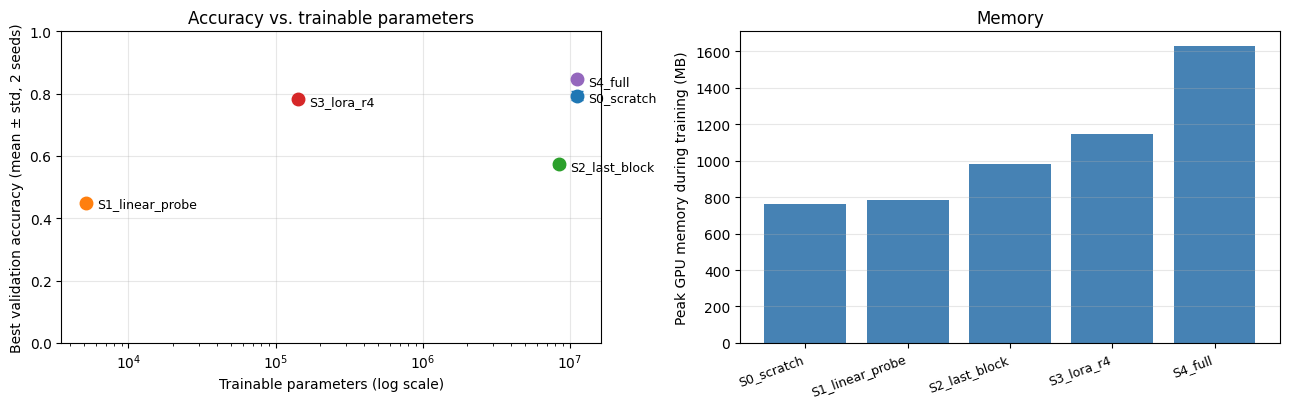

In [18]:
res = summarise(list(STRATEGIES))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for name, r in res.iterrows():
    ax1.errorbar(r['trainable_params'], r['best_val_acc'], yerr=r['best_val_acc_std'], fmt='o', ms=9, capsize=4)
    ax1.annotate(name, (r['trainable_params'], r['best_val_acc']), textcoords='offset points', xytext=(8, -4), fontsize=9)
ax1.set_xscale('log'); ax1.set_ylim(0, 1)
ax1.set_xlabel('Trainable parameters (log scale)'); ax1.set_ylabel('Best validation accuracy (mean ± std, 2 seeds)')
ax1.set_title('Accuracy vs. trainable parameters'); ax1.grid(alpha=0.3)
ax2.bar(range(len(res)), res['peak_memory_MB'], color='steelblue')
ax2.set_xticks(range(len(res))); ax2.set_xticklabels(res.index, rotation=20, ha='right', fontsize=9)
ax2.set_ylabel('Peak GPU memory during training (MB)'); ax2.set_title('Memory'); ax2.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

### 🛠️ Task 2c — where did the network change?

Accuracy tells you *how well* a strategy worked, not *what* it changed. `build_model` stored a copy of
every conv layer's initial weights (`model._init_weights`). Implement `weight_change_by_stage`, which
returns, for each stage, the relative change ‖W − W₀‖ / ‖W₀‖ over all its conv weights.

In [19]:
def weight_change_by_stage(model):
    # Relative change ||W - W0|| / ||W0|| of all conv weights, per stage (conv1, layer1, ..., layer4)
    num, den = {}, {}
    for name, p in model.named_parameters():
        if name in model._init_weights:
            stage = name.split('.')[0]
            w0 = model._init_weights[name]
            w = p.detach().cpu()
            num[stage] = num.get(stage, 0.0) + (w - w0).pow(2).sum().item()      # squared norm of the change
            den[stage] = den.get(stage, 0.0) + w0.pow(2).sum().item()            # squared norm of the initial weights
    return {stage: math.sqrt(num[stage] / den[stage]) for stage in num}


changes = pd.DataFrame({name: weight_change_by_stage(MODELS[(name, 0)]) for name in ['S2_last_block', 'S4_full']})
changes.round(4)

,S2_last_block,S4_full
conv1,0.0000,0.1413
layer1,0.0000,0.4548
layer2,0.0000,0.5660
layer3,0.0000,0.5827
layer4,0.5838,0.3494


**Questions:**

1. **Pretraining.** Compare `S4_full` with `S0_scratch` (and with Lab 7's small CNN, ~78–79% on the same
   2,000 images). How much is ImageNet pretraining worth here, even though ImageNet contains no house
   numbers? What might the pretrained network "know" that is useful for digits?
2. **Linear probe.** How well do frozen ImageNet features separate the ten digits? Can the probe even fit
   the *training* set? Explain using the domain gap between ImageNet photos and house numbers.
3. **Last block.** `S2_last_block` trains 8.4 M parameters, ~60× more than LoRA. Compare its training
   and validation loss, and use the weight-change table from Task 2c: which stages could it change, and
   which would have needed to change? What does that tell you about *where* the adaptation to digits
   has to happen?
4. **LoRA.** LoRA trains ~1.3% of the parameters, spread over all stages. How close does it get to full
   fine-tuning and to training from scratch? Compare its training and validation loss with full
   fine-tuning's: what does the low-rank restriction do?
5. **Memory.** Did LoRA save GPU memory in proportion to its parameter savings? Explain what GPU memory
   is used for during training (weights, gradients, optimiser state, **activations**), and which of these
   LoRA reduces. (Note: the first run in a session can show a much higher peak than later runs with
   identical settings, because cuDNN tries out convolution algorithms (`cudnn.benchmark = True`). Compare
   memory only under identical, warmed-up conditions.)
6. **A cautionary tale.** In an earlier version of this lab, we followed the common advice of a *lower*
   learning rate for pretrained layers: 1e-4 for the backbone, 1e-3 for the head. Full fine-tuning then
   reached only ~56%, far *below* training from scratch (~78%). Measured with Task 2c's function, the
   early layers had changed by less than 2% (`conv1` by 0.4%). Using your own weight-change table,
   explain what went wrong. When *is* a low learning rate for pretrained layers a good idea?
7. **The batch-norm detail.** `fit` keeps the BN statistics of frozen layers fixed. For the linear probe,
   what would happen to the frozen features if the BN layers kept updating their running statistics on
   SVHN images while γ, β and all conv weights stay frozen? Is that necessarily bad?

> ### ✅ Solution and discussion
> **Reference run** (32×32, lr 3e-3, 15 epochs, 2 seeds):
>
> | Strategy | Trainable | Best val. acc. | Train loss | Val loss | Peak memory (MB) |
> |---|---|---|---|---|---|
> | S0 scratch | 11.2 M (100%) | 79.4 ± 1.4% | 0.011 | 0.90 | 719 / 806 |
> | S1 linear probe | 5 k (0.05%) | 45.1 ± 0.1% | 1.28 | 1.62 | 761 / 805 |
> | S2 last block | 8.4 M (75%) | 57.3 ± 0.9% | 0.002 | **2.08** | 944 / 1,020 |
> | S3 LoRA, rank 4 | 143 k (1.3%) | 78.3 ± 0.2% | 0.029 | 1.00 | 1,240 / 1,049 |
> | S4 full fine-tuning | 11.2 M (100%) | **84.6 ± 0.0%** | 0.024 | **0.64** | 2,755 / 503 |
>
> Weight changes (Task 2c), ‖W − W₀‖ / ‖W₀‖:
>
> | Stage | S2 last block | S4 full fine-tuning |
> |---|---|---|
> | conv1 | 0 | 14% |
> | layer1 | 0 | 45% |
> | layer2 | 0 | 57% |
> | layer3 | 0 | 58% |
> | layer4 | 58% | 35% |
>
> Interesting detail: full fine-tuning changed the **middle** stages most, and `layer4` *less* than the last-block strategy did. When the early layers can adapt, the top layer needs to change less.
>
> 1. Pretraining helps: full fine-tuning beats training the same network from scratch by ~5 pp (84.6% vs. 79.4%), and Lab 7's small CNN (~78–79%) by a similar margin, with the same 2,000 images and budget. The early layers of an ImageNet network detect **edges, corners, blobs and textures**, generic building blocks of any image, including digits; it also starts from a well-conditioned network. With 2,000 images, learning these from scratch is hard; reusing them is "more data in another form" (Lab 7).
> 2. Poorly: 45.1%, and the probe can't even fit the training set (training loss 1.28; training accuracy ~58% in a pilot run). The final 512 ImageNet features encode object-level concepts that are not organised by digit identity; a linear layer can only re-weight existing features, not create new ones. On a dataset close to ImageNet (e.g. Oxford Pets from Lab 4) the same probe would be strong. **How useful frozen features are depends on the domain gap.**
> 3. The last block fits the training set perfectly (training loss 0.002) but generalises worst of all the trained strategies (validation loss 2.08): it *memorises* the 2,000 images on top of frozen ImageNet features from `conv1`–`layer3`. The weight-change table shows that it can only change `layer4`, whereas full fine-tuning changes every stage, including the early ones. Together with question 6, this is strong evidence that the adaptation to digits has to happen in the **early and mid-level** layers (strokes and edges at the digits' scale), not only at the top. "Fine-tune only the last layers" is a good default when the new domain is *close* to the pretraining domain, and a poor one here.
> 4. LoRA (78.3%) nearly matches training from scratch (79.4%) with 1.3% of the parameters and gets within ~6 pp of full fine-tuning, while changing *all* stages. Its training loss is similar to full fine-tuning's (0.03 vs. 0.02) but its validation loss is clearly higher (1.00 vs. 0.64): the low-rank restriction limits how much each layer can change, which acts as a regulariser but here also limits the fit. A higher rank (optional cell below) trades parameters for accuracy. LoRA is designed for situations where full fine-tuning is too expensive (memory, storage, many tasks); for an 11 M-parameter network on one task, full fine-tuning is affordable and best.
> 5. Usually **not** in proportion. Training memory = weights + gradients + optimiser state (Adam: 2 values per trainable parameter) + **stored activations**. For ResNet-18, the weights, gradients and Adam state of all 11 M parameters are only ~180 MB; LoRA removes most of the gradients and optimiser state, but the frozen weights must still be stored, activations must still be stored throughout the network (gradients have to flow back through every frozen layer to reach the adapters), and its 16 extra branches add activations. In the reference run LoRA even used *more* peak memory (1.0–1.2 GB) than training from scratch (0.7–0.8 GB). Note also full fine-tuning: 2.8 GB in its first run and 0.5 GB in its second, with identical settings, which is the cuDNN warm-up effect mentioned in the question. For billion-parameter language models, weights and optimiser state dominate, which is where LoRA's memory savings are dramatic.
> 6. With a backbone learning rate of 1e-4, the pretrained layers hardly moved (early layers < 2%): the network kept its ImageNet features, which don't suit digits (question 2), and fitted the training set mainly with its upper layers and head, i.e. it behaved like the last-block strategy and memorised (the earlier version had 56.6% for the last block and 56.3% for full fine-tuning, almost identical). At 3e-3 the early layers change substantially (Task 2c: `conv1` 14%, `layer1` 45%) and full fine-tuning becomes the best strategy. A debugging run confirmed this: raising the backbone learning rate from 1e-4 to 1e-3 improved full fine-tuning by 16–33 pp at every input size. **A low learning rate for pretrained layers is a good idea when the new domain is close to the pretraining domain** (the pretrained features are already right and you want to protect them from a randomly initialised head), and when the dataset is so small that large changes would overfit. When the domain is far away, the features *need* to change, and the learning rate has to allow that. This is exactly why the learning rate must be checked (sweep or range test, Lab 7) rather than taken from a rule of thumb.
> 7. The running statistics would drift towards SVHN's feature statistics. That changes the frozen features at test time, so the "frozen" network isn't really frozen any more, and the head would be trained on features that keep shifting. It is not necessarily bad: re-estimating BN statistics on the target domain is a known, cheap domain-adaptation trick ("AdaBN"). But it must be a *deliberate* choice, reported in the Methods section, not an accident of calling `model.train()`.

### Optional: how does the rank matter?

In [20]:
for rank in [1, 16]:
    fit(f'S3_lora_r{rank}', *build_model('lora', rank=rank, seed=0), seed=0)
summarise(['S1_linear_probe', 'S3_lora_r1', 'S3_lora_r4', 'S3_lora_r16', 'S4_full'])

  [S3_lora_r1 | seed 0] best val acc 0.727 (epoch 11) | trainable 39,498 | train loss 0.191 | peak GPU memory 1159 MB | 9s
  [S3_lora_r16 | seed 0] best val acc 0.814 (epoch 13) | trainable 555,018 | train loss 0.006 | peak GPU memory 1413 MB | 9s


,runs,best_val_acc,best_val_acc_std,trainable_params,train_loss,val_loss,peak_memory_MB,runtime_s,trainable_%
name,,,,,,,,,
S1_linear_probe,2,0.4505,0.0007,5130,1.2780,1.6200,783.0,4.40,0.0459
S3_lora_r1,1,0.7270,NaN,39498,0.1908,0.9478,1159.0,8.70,0.3522
S3_lora_r4,2,0.7828,0.0018,142602,0.0294,0.9976,1144.5,8.80,1.2598
S3_lora_r16,1,0.8140,NaN,555018,0.0061,1.0100,1413.0,9.10,4.7310
S4_full,2,0.8455,0.0000,11181642,0.0239,0.6406,1629.0,10.25,100.0000


**Question:** how does accuracy change with the rank, compared with the change in trainable
parameters? What would you expect for a very large rank?

> ### ✅ Solution and discussion
> **Reference run** (1 seed for ranks 1 and 16): rank 1: **72.7%** (39 k trainable parameters, train loss 0.19); rank 4: **78.3%** (143 k, 0.03); rank 16: **81.4%** (555 k, 0.006). For comparison: from scratch 79.4%, full fine-tuning 84.6%.
>
> Accuracy increases with the rank, with diminishing returns (+5.6 pp from 1 to 4, +3.1 pp from 4 to 16), while the trainable parameters grow ~4× per step. Rank 16 already beats training from scratch with 5% of the parameters.
>
> Even rank 1 beats the linear probe by a wide margin, because it can change the features at *every* layer. The training loss falls with the rank: more rank = more capacity to fit. For a rank as large as the layer itself (r = min(C_out, C_in·k²)), LoRA can represent any change and becomes as expressive as full fine-tuning of those layers, with more parameters than the layer itself. **The rank is a capacity (and regularisation) knob**, and the interesting regime is where a small rank captures most of the benefit: evidence that the needed change is "low-dimensional".

---
## Part 3: Merge and ship

During training, the LoRA network computes W·x + B·(A·x): two extra convolutions per layer. After
training, B·A can be added into W once, and the adapters removed. Let's verify that this is free.

In [21]:
def merge_lora(model):
    '''Returns a copy of `model` in which every LoRAConv2d is replaced by a plain conv with W + ΔW.'''
    merged = copy.deepcopy(model)
    for stage in [merged.layer1, merged.layer2, merged.layer3, merged.layer4]:
        for block in stage:
            for conv_name in ['conv1', 'conv2']:
                m = getattr(block, conv_name)
                if isinstance(m, LoRAConv2d):
                    conv = copy.deepcopy(m.base)
                    with torch.no_grad():
                        conv.weight += m.delta_weight()
                    setattr(block, conv_name, conv)
    return merged


@torch.no_grad()
def time_inference(model, repeats=5):
    model.eval()
    xb = prep(x_val[:256], model)
    model(xb)                                            # warm-up
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(repeats):
        model(xb)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return (time.time() - t0) / repeats * 1000


lora_model = MODELS[('S3_lora_r4', 0)]
merged_model = merge_lora(lora_model)
with torch.no_grad():
    lora_model.eval(); merged_model.eval()
    a, b = lora_model(prep(x_val[:512], lora_model)), merged_model(prep(x_val[:512], merged_model))
print(f'Max logit difference after merging: {(a - b).abs().max().item():.1e}')
print(f'Same predictions on 512 validation images: {bool((a.argmax(1) == b.argmax(1)).all())}')
print(f'Validation accuracy -- LoRA: {evaluate(lora_model, x_val, y_val)[1]:.4f} | merged: {evaluate(merged_model, x_val, y_val)[1]:.4f}')
print(f'Inference time per 256 images -- LoRA: {time_inference(lora_model):.1f} ms | merged: {time_inference(merged_model):.1f} ms '
      f'| original ResNet-18: {time_inference(build_model("full")[0]):.1f} ms')

adapter_bytes = sum(p.numel() for n, p in lora_model.named_parameters() if p.requires_grad) * 4
full_bytes = count_params(merged_model, False) * 4
print(f'Storage: LoRA adapter + head {adapter_bytes / 2**10:.0f} KB vs. full model {full_bytes / 2**20:.1f} MB')

Max logit difference after merging: 6.4e-05
Same predictions on 512 validation images: True
Validation accuracy -- LoRA: 0.7815 | merged: 0.7815
Inference time per 256 images -- LoRA: 13.2 ms | merged: 10.1 ms | original ResNet-18: 8.7 ms
Storage: LoRA adapter + head 557 KB vs. full model 42.7 MB


**Questions:**

1. Why is merging *exact* (up to rounding)? Which property of the LoRA path makes it possible? Would it still
   be possible if we put a ReLU between A and B?
2. Merging gives you a standard ResNet-18 again. What does that mean for deployment?
3. The adapter is a few hundred KB, the full model ~45 MB. Imagine you need models for 20 different
   tasks (or 20 hospitals, or 20 cameras) that share one backbone. What does LoRA make possible?

> ### ✅ Solution and discussion
> **Reference run:** max logit difference after merging 6.4 × 10⁻⁵ (floating-point rounding), identical predictions, identical validation accuracy (78.15%). Inference per 256 images: LoRA 13.2 ms, merged 10.1 ms, original ResNet-18 8.7 ms. Storage: adapter + head 557 KB vs. full model 42.7 MB (≈ 1/78).
>
> 1. The LoRA path B·(A·x) is a composition of two **linear** maps (two convolutions without a nonlinearity), so it equals a single linear map ΔW·x, and W·x + ΔW·x = (W + ΔW)·x. A ReLU between A and B would make the path nonlinear: ReLU(A·x) can't be expressed as a convolution of x, so it could no longer be folded into W. (This is the same linearity argument as in the grayscale surgery of Part 1.)
> 2. After merging, the model has exactly the architecture, size and speed of the original ResNet-18: no special code, no extra layers, no inference overhead. Any tool that can run a ResNet-18 can run the fine-tuned model. The unmerged LoRA model is ~30% slower (16 extra small convolutions); the merged one runs at about the original speed. (At 32×32 the timings are a few milliseconds and noisy, so compare them only roughly.)
> 3. You can store **one** backbone (45 MB) and 20 adapters (a few hundred KB each), and switch tasks by swapping adapters, or merge on the fly. Training each task is also cheaper. This is how large language and diffusion models are customised in practice (thousands of LoRA adapters are shared online for one base model).

---
## Part 4: Operating on *your* network — an idea generator

You've now operated on the input, on what is trained, and on the trained weights themselves. The
table below generalises this. It's a menu of operations that are each a few lines of code, the
kind of change that can turn a standard project into an investigation.

| Operate on… | Operation | What it lets you do / test | Example in a project |
|---|---|---|---|
| **Input** | Change the number of input channels (Part 1) | Use non-RGB data with a pretrained network | grayscale X-rays, multispectral satellite bands, RGB + depth |
| | Input ablation (Part 1) | Find out which information the model actually uses | Does it need colour? The infrared band? |
| | Change the input resolution | Trade detail for speed | Small lesions vs. speed of training |
| **Output** | Replace the head | Solve a different task with the same features | regression (age, a severity score), several labels per image |
| | Add a second head + a second loss | Multi-task learning (Lecture 6) | classify *and* segment; predict the class and a bounding box |
| | Attach a decoder to a pretrained encoder | Segmentation with a pretrained backbone (Lecture 8) | a U-Net with a ResNet encoder |
| **Fusion** | Concatenate a non-image vector to the features before `fc` | Combine images with metadata | patient age/sex, GPS location, camera settings |
| **What to train** | Freeze / partially fine-tune / LoRA (Part 2) | Find out *where* adaptation is needed; save memory and storage | Which stages need to change for your domain? |
| | Different learning rates for different parts | Protect pretrained features | low lr for the backbone, high lr for the new head |
| | Freeze or re-estimate BN statistics | Control domain adaptation | images from a new scanner or hospital |
| **Trained weights** | Merge adapters, average weights, ensemble (Lab 7) | Combine models at no or low cost | one backbone, several adapters |

As an example of how small these operations are, here is **metadata fusion**: an image network plus a
vector of extra information, joined just before the classifier.

In [22]:
class ImageMetadataNet(nn.Module):
    '''A pretrained CNN whose penultimate features are concatenated with a metadata vector.'''
    def __init__(self, n_meta, num_classes):
        super().__init__()
        self.cnn = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        n_img = self.cnn.fc.in_features
        self.cnn.fc = nn.Identity()                                  # keep the 512 image features
        self.meta = nn.Sequential(nn.Linear(n_meta, 32), nn.ReLU())  # embed the metadata
        self.head = nn.Linear(n_img + 32, num_classes)

    def forward(self, image, metadata):
        return self.head(torch.cat([self.cnn(image), self.meta(metadata)], dim=1))


demo = ImageMetadataNet(n_meta=3, num_classes=2)
print(demo(torch.randn(4, 3, 64, 64), torch.randn(4, 3)).shape)       # e.g. metadata = (age, sex, scanner id)

torch.Size([4, 2])


### Your turn (with your group, ~20 minutes)

Pick **two** operations from the table (or invent your own) that could make sense for your project.
For each one, write down in your iteration log (Part B of this week's pages):

1. **The question it would answer**: not "it might improve accuracy", but "does our model need X?",
   "where does the adaptation happen?", "is the metadata a shortcut?"…
2. **The single change** compared with your current baseline.
3. **What you predict**, for both a mechanism you can measure and the outcome (as in Lab 7).
4. **The cost**: implementation time and number of runs, from your Week 6 budget.

Discuss your two ideas with a TA, and keep the better one as a candidate for your next iteration.

---
## Part 5: Exam-style questions

Answer these briefly, in your own words, without running code.

1. A 3×3 convolution maps 256 to 256 channels (no bias). How many parameters does it have? How many
   does a rank-8 LoRA adapter for it add? What fraction is that?
2. Explain why a grayscale image can be fed to an RGB-pretrained network *either* by repeating it three
   times *or* by summing the first layer's filters, and why both give the same result.
3. Both LoRA and a ResNet bottleneck block use a 1×1 convolution to change the number of channels. What is
   the purpose of the 1×1 convolution in each case?
4. You fine-tune a network with all its parameters frozen except the classifier, but you forget to put the
   batch-norm layers in eval mode. Your validation accuracy changes even though no conv weight changed.
   Explain why.
5. Why does LoRA save much more memory when fine-tuning a large language model than when fine-tuning a small
   CNN on 32×32 images?

> ### ✅ Solution and discussion
> 1. 3 × 3 × 256 × 256 = **589,824** parameters. A rank-8 adapter adds A: 8 × 256 × 3 × 3 = 18,432 and B: 256 × 8 = 2,048, so **20,480** parameters, ≈ **3.5%** of the layer.
> 2. Convolution is linear in the input channels: the first layer computes Σ_c W_c ∗ x_c. If all three channels equal g, this is Σ_c W_c ∗ g = (Σ_c W_c) ∗ g. So repeating g three times through the original filters equals passing g once through the summed filter. Both are exactly the same computation (summing is cheaper).
> 3. In a **ResNet bottleneck**, the 1×1 conv reduces (and later restores) the number of channels around the expensive 3×3 conv, to cut the computation and the parameters of the *layer itself*. In **LoRA**, the narrow k×k conv A maps to r ≪ C channels and the 1×1 conv B maps back to C_out, so that the *change* to a frozen layer is low-rank and cheap to learn and store. Same factorisation idea, different purpose: an efficient architecture vs. an efficient update.
> 4. In train mode, batch norm normalises with the statistics of the current batch and updates its running mean and variance, which are buffers, not parameters, so freezing the parameters doesn't stop them changing. At test time the network then uses the new running statistics, so the features of the "frozen" layers have changed, and so has the accuracy.
> 5. Training memory consists of the weights, their gradients and the optimiser state (Adam stores two extra values per trainable parameter) plus the activations. In a large language model, weights, gradients and optimiser state of billions of parameters dominate, and LoRA removes the gradients and optimiser state of almost all of them. In a small CNN on small images, the stored **activations** are a large share of the memory, and LoRA does not reduce them (gradients must still flow back through every frozen layer). Its extra branches even add activations: in this lab, LoRA used *more* peak memory than training from scratch.

---
## Wrapping up

The point of today wasn't LoRA or grayscale surgery as such. It was the shift in perspective:

> **The networks from the lecture are not fixed recipes. You can change their inputs, their outputs, what
> is trained, and how — and each such change can become a controlled experiment in your project.**

Now open **`Lab8_IterationLog_Week8.md`** with your group.